<a href="https://colab.research.google.com/github/Niklas-Hy/Deeplearning/blob/main/Kopia_av_Exercise_6_2_KERAS_complicated_function.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 6.2
## Interpolation
In this task, we implement a simple NN to learn a complicated function.

In [ ]:
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt

layers = keras.layers

plt.style.use("seaborn-v0_8")

### Generation of data

In [ ]:
def some_complicated_function(x):
    return (
        (np.abs(x)) ** 0.5
        + 0.1 * x
        + 0.01 * x ** 2
        + 1
        - np.sin(x)
        + 0.5 * np.exp(x / 10.0)
        ) / (0.5 + np.abs(np.cos(x)))

Let's simulate the train data

In [ ]:
N_train = 10**4  # number of training samples

rng = np.random.default_rng()

# Note: "[:, np.newaxis]" reshapes array to (N,1) as required by our DNN
# (we input one feature per sample)
xtrain = rng.uniform(-10, 10, N_train)[:, np.newaxis]
ytrain = some_complicated_function(xtrain) + rng.standard_normal(
    xtrain.shape
)  # train data includes some noise

In [ ]:
print(f"{xtrain.shape = }")
print(f"{ytrain.shape = }")

xtrain.shape = (10000, 1)
ytrain.shape = (10000, 1)


Simulate test data

In [ ]:
N_test = 10000  # number of testing samples

xtest = np.linspace(-10, 10, N_test)
ytest = some_complicated_function(xtest)

In [ ]:
x_scale = 10.0
xtrain_n = xtrain / x_scale
xtest_n = xtest / x_scale

In [ ]:
print(f"{xtest.shape = }")
print(f"{ytest.shape = }")

xtest.shape = (10000,)
ytest.shape = (10000,)


### Define Model

Define the number of nodes, the number of layers, and choose an activation function.
Use `keras.regularizers` to use parameter norm penalties or add a dropout layer via `layers.Dropout(fraction)`.

You may use the skeleton below:

In [ ]:
nb_nodes = 100
nb_layers = 8
activation = "relu"

model = keras.models.Sequential(name="1Dfit")
model.add(
    layers.Dense(
        nb_nodes,
        activation=activation,
        input_dim=xtrain.shape[1]
    )
)
for i in range(1, nb_layers):
  model.add(layers.Dense(nb_nodes, activation=activation))

model.add(layers.Dense(1))  # final layer

print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "1Dfit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 100)            │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,001 (277.35 KB)

 Trainable params: 71,001 (277.35 KB)

 Non-trainable params: 0 (0.00 B)

None


8 hidden layers with 100 ReLU nodes each and one linear output node (71,001 parameters). No regularization was used.

### Compile the model (set an objective and choose an optimizer)

Choose an optimizer from `keras.optimizers`, e.g., `adam = keras.optimizers.Adam(learning_rate=0.001)`.

Further, choose the correct objective (loss) for this <b>regression task</b>.

In [ ]:
adam = keras.optimizers.Adam(learning_rate=0.001)
model.compile(loss="MSE", optimizer=adam)

MSE loss because this is a regression task, and the Adam optimizer with learning rate 0.001.

### Train the model

Train the network for a couple of epochs and save the model several times in between.

In [ ]:
epochs = 200
save_period = 20 # after how many epochs the model should be saved?

chkpnt_saver = keras.callbacks.ModelCheckpoint(
    "weights-{epoch:02d}.weights.h5",
    save_weights_only=True,
    save_freq=save_period
)

results = model.fit(
    xtrain_n,
    ytrain,
    batch_size=64,
    epochs=epochs,
    verbose=1,
    callbacks=[chkpnt_saver]
)

Epoch 1/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 4.7193
Epoch 2/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.1787
Epoch 3/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.8029
Epoch 4/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.5856
Epoch 5/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.3201
Epoch 6/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.0687
Epoch 7/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.7178
Epoch 8/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.4792
Epoch 9/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.4329
Epoch 10/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.2813
Epoch 11/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2468
Epoch 12/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.2682
Epoch 13/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.2532
Epoch 14/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.2354
Epoch 15/200
157/157 ━━━━━━━━━━━━━━━━━━━━ 

Trained for 200 epochs with batch size 64. The loss drops from about 4.8 ish to 1.07. It can’t go much lower because the training data has noise with variance 1.

Compare the performance of the model during the training. You may use the skeleton below:

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


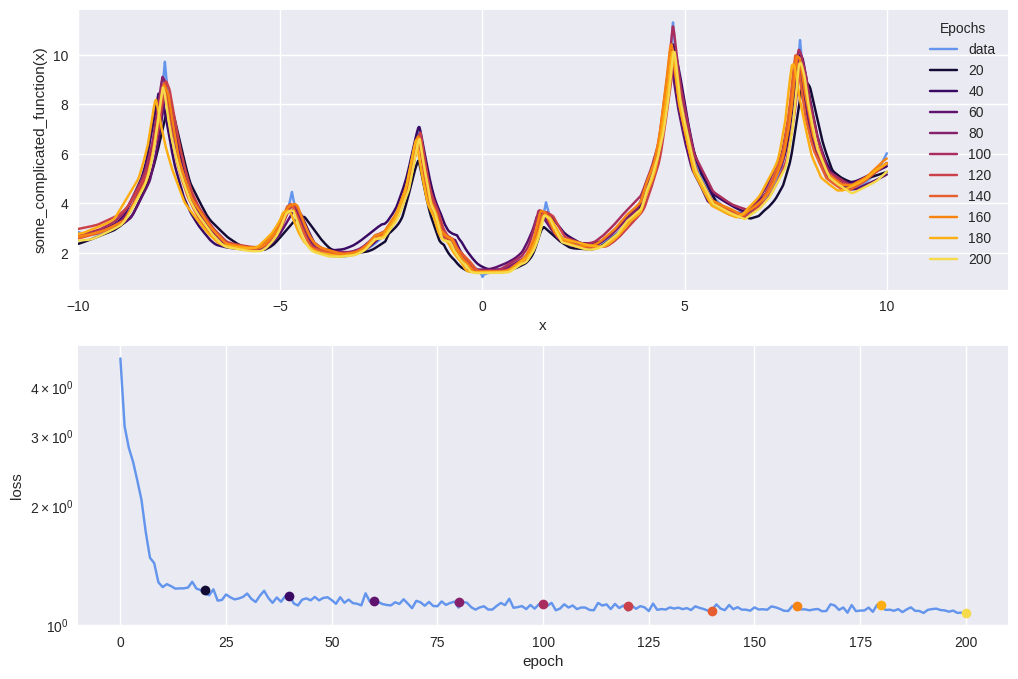

In [ ]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(12, 8))

ax1.plot(xtest, ytest, color="#6495ED", label="data")
saved_epochs = range(save_period, epochs + 1, save_period)

colors = [
    plt.cm.inferno((i + 1) / float(len(saved_epochs) + 1))
    for i in range(len(saved_epochs))
]

for i, epoch in enumerate(saved_epochs):
    model.load_weights("weights-{epoch:02d}.weights.h5".format(epoch=epoch))
    ypredict = model.predict(xtest_n).squeeze()
    ax1.plot(xtest.squeeze(), ypredict, color=colors[i], label=epoch)
    ax2.plot(
        epoch,
        results.history["loss"][epoch - 1],
        color=colors[i],
        marker="o",
        zorder=10,
    )

ax1.set(xlabel="x", ylabel="some_complicated_function(x)", xlim=(-10, 13), title="")
ax1.grid(True)
ax1.legend(loc="upper right", title="Epochs")

ax2.plot(results.history["loss"], color="#6495ED")
ax2.set(xlabel="epoch", ylabel="loss")
ax2.grid(True)
ax2.semilogy()

plt.show()

After 20 epochs the network already follows the true function, including all peaks. Later epochs mainly sharpen the tallest peaks. The predictions don’t follow the noise, so the model generalizes well.